What the notebook does: Receives text/essay from user, parallelly evaluates them on the basis of points being bought up, grammar and vocabulary depth, gives a text feedback and an integer score from 0 to 10. We then give these feedbacks to a summarizing llm to generate a summary feedback, as well as calculcate mean of individual scores

In [1]:
import operator
from typing import Annotated, TypedDict

from langgraph.graph import END, START, StateGraph
from pydantic import BaseModel, Field

In [2]:
# Pydantic model to describe output schema
class LlmOutputSchema(BaseModel):
    text_feedback: str = Field(description='30 word textual feeback after analysis of essay text')

    score: int = Field(description='Integer score based on the analysis of essay text. The score ranges from 0 to 10, with 0 being the lowest and 10 being the highest', ge=0, le=10)


# TypedDict state class for graph
class EssayReviewState(TypedDict):
    essay_topic: str
    essay_text: str
    points_feedback: str
    grammar_feedback: str
    vocabulary_feedback: str
    overall_feedback: str
    individual_scores: Annotated[list[int], operator.add]
    final_score: float


In [3]:
# structured_llm = ChatOpenRouter(
#     model="nvidia/nemotron-3-super-120b-a12b:free"
# ).with_structured_output(LlmOutputSchema)


from langchain_openai import ChatOpenAI

llm = ChatOpenAI(
    model='local qwen3.5:4b_q8',
    base_url='http://127.0.0.1:8080/v1',
    api_key='not needed' #type: ignore
)

structured_llm = llm.with_structured_output(LlmOutputSchema)

In [4]:
from langchain_core.prompts import PromptTemplate

In [5]:
points_template = PromptTemplate(
    input_variables=['essay_topic', 'essay_text'],
    template='''
    You are an experienced essay evaluator. Your job is analyse the following essay and evaluate it solely based on the relevance, depth and creativity of the points brought up in the essay for the given topic.

    Essay topic: {essay_topic}

    Essay text: {essay_text}

    Evaluate solely on the basis of the strength of points brought up in the text, not on basis of vocabulary depth, grammatical correctness etc    
'''
)

grammar_template = PromptTemplate(
    input_variables=['essay_topic', 'essay_text'],
    template='''
    You are an experienced essay evaluator. Your job is analyse the following essay and evaluate it solely based on grammatical correctness of the essay text

    Essay topic: {essay_topic}

    Essay text: {essay_text}

    Evaluate solely based on how grammatically correct the essay text is, and not on the basis of strength of points brought up, vocabulary depth etc
'''
)

vocabulary_template = PromptTemplate(
    input_variables=['essay_topic', 'essay_text'],
    template='''
    You are an experienced essay evaluator. Your job is analyse the following essay and evaluate it solely based on the vocabulary depth in the essay text

    Essay topic: {essay_topic}

    Essay text: {essay_text}

    Evaluate solely on the basis of the the words used on the depth of vocabulary used in the essay text and the exquisiteness of the words used.
'''
)

summary_template = PromptTemplate(
    input_variables=['points_feedback', 'grammar_feedback', 'vocabulary_feedback'],
    template='''
    Your goal is to summarise the provided feedbacks and provide an overall feedback of 40-60 words.

    Points feedback: {points_feedback}

    Grammar feedback: {grammar_feedback}

    Vocabulary feedback: {vocabulary_feedback}

    Generate an overall summarised feedback from the above feedbacks
'''
)

In [6]:
from langchain_core.output_parsers import StrOutputParser

In [7]:
points_chain = points_template | structured_llm
grammar_chain = grammar_template | structured_llm
vocabulary_chain = vocabulary_template | structured_llm
overall_feedback_chain = summary_template | llm | StrOutputParser()

In [8]:
def evaluate_points(state: EssayReviewState):
    llm_output = points_chain.invoke({
        'essay_topic': state['essay_topic'],
        'essay_text': state['essay_text']
    })
    text_feedback = llm_output.text_feedback #type: ignore
    score = llm_output.score #type: ignore

    return {'points_feedback': text_feedback, 'individual_scores': [score]}


def evaluate_grammar(state: EssayReviewState):
    llm_output = grammar_chain.invoke({
        'essay_topic': state['essay_topic'],
        'essay_text': state['essay_text']
    })
    text_feedback = llm_output.text_feedback #type: ignore
    score = llm_output.score #type: ignore

    return {'grammar_feedback': text_feedback, 'individual_scores': [score]}


def evaluate_vocabulary(state: EssayReviewState):
    llm_output = vocabulary_chain.invoke({
        'essay_topic': state['essay_topic'],
        'essay_text': state['essay_text']
    })
    text_feedback = llm_output.text_feedback #type: ignore
    score = llm_output.score #type: ignore

    return {'vocabulary_feedback': text_feedback, 'individual_scores': [score]}


def generate_final_feedback_and_score(state: EssayReviewState):
    points_feedback = state['points_feedback']
    grammar_feedback = state['grammar_feedback']
    vocabulary_feedback = state['vocabulary_feedback']

    overall_feedback = overall_feedback_chain.invoke({
        'points_feedback': points_feedback,
        'grammar_feedback': grammar_feedback,
        'vocabulary_feedback': vocabulary_feedback
    })
    final_score = sum(state['individual_scores']) / len(state['individual_scores'])

    return {'overall_feedback': overall_feedback, 'final_score': round(final_score, 3)}

In [9]:
graph = StateGraph(EssayReviewState)

graph.add_node('evaluate_points', evaluate_points)
graph.add_node('evaluate_grammar', evaluate_grammar)
graph.add_node('evaluate_vocabulary', evaluate_vocabulary)
graph.add_node('generate_final_feedback_and_score', generate_final_feedback_and_score)


graph.add_edge(START, 'evaluate_points')
graph.add_edge(START, 'evaluate_grammar')
graph.add_edge(START, 'evaluate_vocabulary')

graph.add_edge('evaluate_points', 'generate_final_feedback_and_score')
graph.add_edge('evaluate_grammar', 'generate_final_feedback_and_score')
graph.add_edge('evaluate_vocabulary', 'generate_final_feedback_and_score')

graph.add_edge('generate_final_feedback_and_score', END)


workflow = graph.compile()

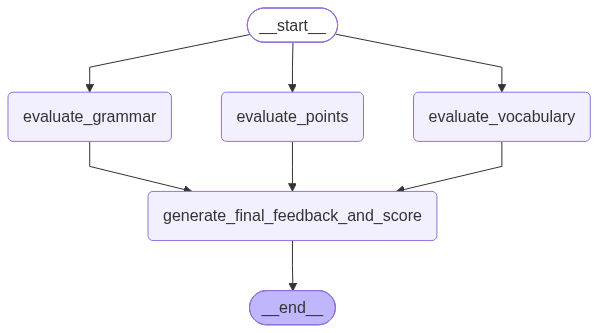

In [10]:
workflow

In [11]:
initial_state = {
    'essay_topic': 'Pillows',
    'essay_text': "Pillows are essential items that provide comfort and support while sleeping. They help maintain proper head and neck alignment, allowing people to rest peacefully throughout the night. Pillows come in various shapes, sizes, and materials, including cotton, memory foam, feathers, and polyester. Choosing the right pillow depends on personal preferences and sleeping positions. Besides sleeping, pillows can also be used for decoration and relaxation. Regularly washing pillow covers and replacing old pillows helps maintain hygiene and improve sleep quality, making pillows an important part of everyday life."
}

output_state = workflow.invoke(initial_state) #type: ignore

In [12]:
output_state

{'essay_topic': 'Pillows',
 'essay_text': 'Pillows are essential items that provide comfort and support while sleeping. They help maintain proper head and neck alignment, allowing people to rest peacefully throughout the night. Pillows come in various shapes, sizes, and materials, including cotton, memory foam, feathers, and polyester. Choosing the right pillow depends on personal preferences and sleeping positions. Besides sleeping, pillows can also be used for decoration and relaxation. Regularly washing pillow covers and replacing old pillows helps maintain hygiene and improve sleep quality, making pillows an important part of everyday life.',
 'points_feedback': "The essay provides a comprehensive and logically structured overview of the topic 'Pillows.' The points brought up are highly relevant and cover the subject from multiple necessary angles: functional utility (support and alignment), variety (materials and shapes), user-centric selection criteria, secondary uses (decoration

In [ ]:
from IPython.display import display, Markdown


for key, value in output_state.items():
    display(Markdown(f'{key.capitalize()}\n{value}\n\n---'))

Essay_topic
Pillows

---

Essay_text
Pillows are essential items that provide comfort and support while sleeping. They help maintain proper head and neck alignment, allowing people to rest peacefully throughout the night. Pillows come in various shapes, sizes, and materials, including cotton, memory foam, feathers, and polyester. Choosing the right pillow depends on personal preferences and sleeping positions. Besides sleeping, pillows can also be used for decoration and relaxation. Regularly washing pillow covers and replacing old pillows helps maintain hygiene and improve sleep quality, making pillows an important part of everyday life.

---

Points_feedback
The essay provides a comprehensive and logically structured overview of the topic 'Pillows.' The points brought up are highly relevant and cover the subject from multiple necessary angles: functional utility (support and alignment), variety (materials and shapes), user-centric selection criteria, secondary uses (decoration/relaxation), and maintenance (hygiene and replacement). 

In terms of depth, the essay successfully moves beyond a superficial definition by connecting the physical attributes of pillows to specific physiological benefits (head and neck alignment) and long-term care requirements. The inclusion of the maintenance aspect adds a layer of practical depth that distinguishes the piece from a simple list of facts.

Regarding creativity, the approach is methodical rather than novel, which is appropriate for a general informational topic. However, the essay could be considered more creative by incorporating specific, vivid examples of how different pillow types influence specific sleep disorders or by weaving together a narrative that highlights the emotional connection people have with their chosen pillows. As it stands, the points are accurate and well-reasoned, offering a solid, well-rounded perspective on the subject.

---

Grammar_feedback
The essay text is grammatically correct. It follows a logical structure with a clear topic sentence, supporting details, and a concluding sentence. All sentences exhibit proper subject-verb agreement, correct punctuation (commas, periods), and appropriate word order. There are no spelling errors, fragmented sentences, or incorrect verb tenses. The use of transition words (including, besides, helping) is natural and does not disrupt the sentence structure.

---

Vocabulary_feedback
The vocabulary in this essay is functional but lacks depth or sophistication. It relies heavily on basic, common nouns and adjectives (e.g., 'essential,' 'comfort,' 'support,' 'various,' 'depending,' 'preferences,' 'important') that are accessible to early learners or native speakers at a beginner level. There is no use of nuanced vocabulary, idiomatic expressions, or precise descriptors to enhance the tone. The word 'exquisiteness' of the language is notably absent; the phrasing is straightforward and utilitarian rather than polished or evocative. While the sentence structure is clear, the lexical range is narrow, failing to elevate the discussion beyond simple factual statements.

---

Overall_feedback
The essay offers a logically structured and grammatically flawless overview of pillows, covering functional, practical, and maintenance aspects. However, its vocabulary is overly simplistic and lacks sophistication, limiting its expressive depth. While accurate and well-reasoned, the piece remains factual rather than engaging, missing opportunities for vivid detail or nuanced language to elevate the discussion.

---

Individual_scores
[10, 8, 3]

---

Final_score
7.0

---